# Análisis de Incidencias en Rodalies Renfe
## 1. Descripción del Proyecto

Este cuaderno tiene como objetivo explorar, limpiar y analizar el conjunto de datos de incidencias en la red de Rodalies Renfe. A través de este análisis se busca identificar patrones temporales, las líneas y tramos más afectados, la distribución del tipo de incidencias y el impacto en los tiempos de retraso de los usuarios.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import re

# Configuració de la visualització
pd.set_option('display.max_columns', None)
sns.set_theme(style="darkgrid")

# Càrrega del fitxer CSV des de la ruta especificada
data_path = Path("processed/rodalies/Incidencias_Rodalies_es.csv")
if not data_path.exists():
    data_path = Path("..") / data_path

df = pd.read_csv(data_path)

# Inspecció bàsica de volum i primers registres
print(f"Dimensions del dataset: {df.shape[0]} files x {df.shape[1]} columnes\n")
df.head()

Dimensions del dataset: 160 files x 16 columnes



,id_incidencia,fecha,día_semana,mes,línea,place,tipo_incidencia,descripción,horario / duración,minutos_retraso,fuente,tipo_fuente,URL,gravedad,notas,provincia
0,1,18/01/2023,Miércoles,Enero,"R2 Sud, R13, R14, R15, R16, R17",Estació de França–Passeig de Gràcia,Avería en un tren,Retrasos superiores a 40 minutos,No especificada,15,Nació,Prensa,https://naciodigital.cat/societat/rodalies-acu...,Alta,NaN,Barcelona
1,2,26/01/2023,Jueves,Enero,"R2 Nord, R11",Sant Andreu–Montcada i Reixac,Incidencia en las instalaciones de Adif,Afectaciones a la circulaciónn,No especificada,NaN,Cambra de Comerç de Barcelona,Prensa,https://cambrabcn.org/wp-content/uploads/2024/...,Alta,NaN,Barcelona
2,3,31/01/2023,Martes,Enero,R1,Vilassar de Mar–Mataró,Incidencia en las instalaciones de Adif,Afectaciones a la circulaciónn,No especificada,NaN,Cambra de Comerç de Barcelona,Prensa,https://cambrabcn.org/wp-content/uploads/2024/...,Media,NaN,Barcelona
3,4,01/02/2023,Miércoles,Febrero,R4,Sabadell–Terrassa,Incidencia en las instalaciones de suministro ...,Afectaciones a la circulaciónn,No especificada,NaN,Cambra de Comerç de Barcelona,Prensa,https://cambrabcn.org/wp-content/uploads/2024/...,Alta,NaN,Barcelona
4,5,01/02/2023,Miércoles,Febrero,"R7, R8",No especificat,Incidencia en las instalaciones de Adif,Afectaciones a la circulaciónn,No especificada,NaN,Cambra de Comerç de Barcelona,Prensa,https://cambrabcn.org/wp-content/uploads/2024/...,Media,NaN,Barcelona


### Preprocesamiento de los datos
Fechas transformadas a formato dd/mm/yyyy, definición del orden de la gravedad de la incidencia y extracción del tiempo de retraso en formato numérico

In [19]:
# 2. Conversión a formato datetime
df['fecha'] = pd.to_datetime(df['fecha'], format='%d/%m/%Y', errors='coerce')

# 3. Conversión de gravedad a Categoría Ordinal
orden_gravedad = ['Baja', 'Media', 'Alta', 'Muy alta']
df['gravedad'] = pd.Categorical(df['gravedad'], categories=orden_gravedad, ordered=True)

# 4. Extracción de minutos numéricos a partir del texto
def extraer_minutos(val):
    if pd.isna(val) or str(val).strip().lower() in ['no especifica', 'no especificada']:
        return np.nan
    val_str = str(val).lower()
    # Conversión de horas aisladas (ej. 4h, 12h)
    if 'h' in val_str and 'min' not in val_str:
        match = re.search(r'(\d+)', val_str)
        if match:
            return float(match.group(1)) * 60
    # Extracción de números en rangos o valores directos
    numeros = [float(n) for n in re.findall(r'\d+', val_str)]
    return np.mean(numeros) if numeros else np.nan

df['minutos_retraso_num'] = df['minutos_retraso'].apply(extraer_minutos)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 160 entries, 0 to 159
Data columns (total 17 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   id_incidencia        160 non-null    int64         
 1   fecha                157 non-null    datetime64[us]
 2   día_semana           160 non-null    str           
 3   mes                  160 non-null    str           
 4   línea                160 non-null    str           
 5   place                160 non-null    str           
 6   tipo_incidencia      160 non-null    str           
 7   descripción          160 non-null    str           
 8   horario / duración   160 non-null    str           
 9   minutos_retraso      78 non-null     str           
 10  fuente               160 non-null    str           
 11  tipo_fuente          160 non-null    str           
 12  URL                  160 non-null    str           
 13  gravedad             160 non-null    category 

### Clasificación 2 — Desagregación por Líneas Individuales
Desglosamiento de la afectación en múltiples líneas y ordenadas por numero de incidencias


In [37]:
# Reemplazar delimitadores y separar líneas en listas
df_lineas = df.copy()
df_lineas['linea_split'] = df_lineas['línea'].str.replace(';', ',').str.split(',')

# Expandir cada línea a una fila independiente
df_exploded = df_lineas.explode('linea_split')
df_exploded['linea_limpia'] = df_exploded['linea_split'].str.strip()

# Resumen de incidencias por línea de tren
resumen_lineas = df_exploded.groupby('linea_limpia').agg(
    total_incidencias=('id_incidencia', 'count'),
    incidencias_altas=('gravedad', lambda x: (x.isin(['Alta', 'Muy alta'])).sum()),
    promedio_retraso=('minutos_retraso_num', 'mean'),
    retraso_total=('minutos_retraso_num', 'sum')
).reset_index().sort_values(by='total_incidencias', ascending=False).reset_index(drop=True)

resumen_lineas.head(15)

,linea_limpia,total_incidencias,incidencias_altas,promedio_retraso,retraso_total
0,R4,50,31,39.456522,907.5
1,R2 Sud,40,29,93.809524,1970.0
2,R3,39,24,70.384615,915.0
3,R1,33,20,46.590909,512.5
4,R15,33,24,124.833333,1872.5
5,R14,27,18,125.178571,1752.5
6,R13,27,21,141.041667,1692.5
7,R16,27,23,136.153846,1770.0
8,R17,26,22,27.500000,330.0
9,R2 Nord,24,20,38.409091,422.5


### Clasificación 4 — Matriz Temporal (Día de la Semana vs. Gravedad)
Organiza los datos según la recurrencia temporal para determinar qué días de la semana sufren mayor perturbación en el servicio.

In [39]:
# Definir orden lógico de días de la semana
dias_ordenados = ['Lunes', 'Martes', 'Miércoles', 'Jueves', 'Viernes', 'Sábado', 'Domingo']
df['día_semana'] = pd.Categorical(df['día_semana'], categories=dias_ordenados, ordered=True)

# Tabla cruzada: Día de la semana vs Gravedad
matriz_temporal = pd.crosstab(
    df['día_semana'],
    df['gravedad'],
    margins=True,
    margins_name='Total'
)

matriz_temporal


gravedad,Baja,Media,Alta,Muy alta,Total
día_semana,,,,,
Lunes,6,7,14,1,28
Martes,1,8,15,1,25
Miércoles,3,8,16,1,28
Jueves,1,8,14,3,26
Viernes,3,5,18,0,26
Sábado,0,4,5,0,9
Domingo,0,9,8,1,18
Total,14,49,90,7,160


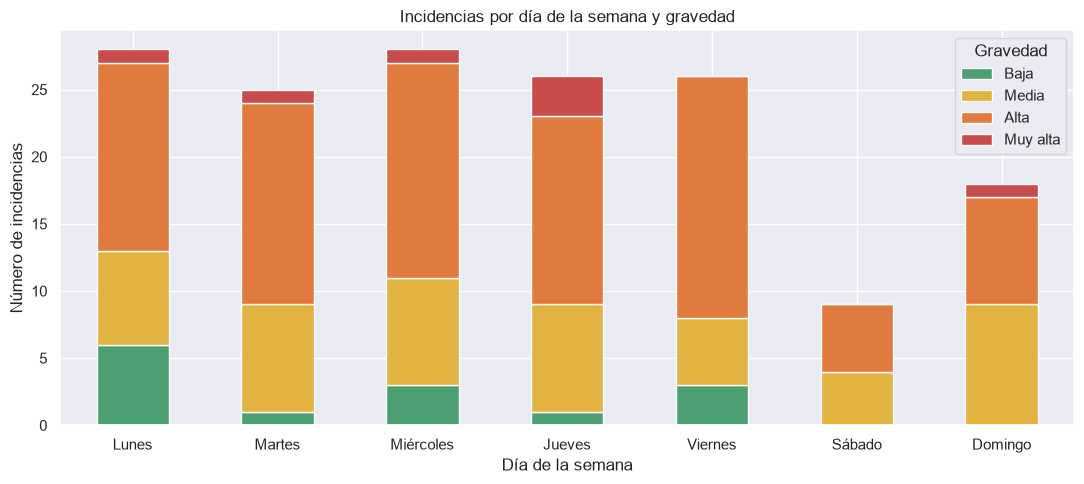

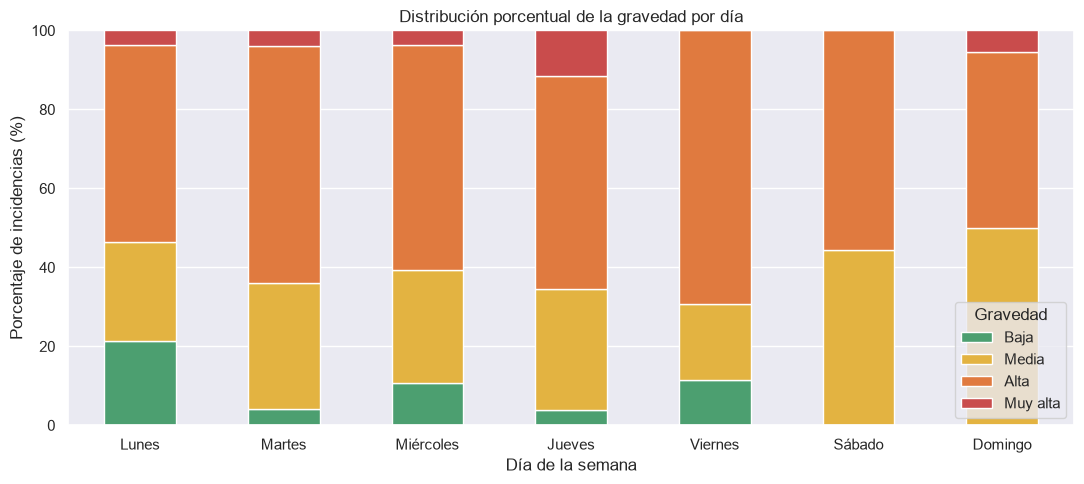

In [40]:

# Preparar los datos para los gráficos, sin la fila ni la columna de totales
matriz_grafico = matriz_temporal.drop(index='Total', columns='Total', errors='ignore')
colores_gravedad = {
    'Baja': '#4C9F70',
    'Media': '#E3B341',
    'Alta': '#E07A3F',
    'Muy alta': '#C94C4C'
}
colores = [colores_gravedad.get(columna, '#777777') for columna in matriz_grafico.columns]

# Gráfico 1: número de incidencias por día y gravedad
ax = matriz_grafico.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 5),
    color=colores,
    edgecolor='white'
)
ax.set_title('Incidencias por día de la semana y gravedad')
ax.set_xlabel('Día de la semana')
ax.set_ylabel('Número de incidencias')
ax.legend(title='Gravedad')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Gráfico 2: porcentaje de cada gravedad dentro de cada día
matriz_porcentajes = matriz_grafico.div(matriz_grafico.sum(axis=1).replace(0, np.nan), axis=0) * 100
ax = matriz_porcentajes.plot(
    kind='bar',
    stacked=True,
    figsize=(11, 5),
    color=colores,
    edgecolor='white'
)
ax.set_title('Distribución porcentual de la gravedad por día')
ax.set_xlabel('Día de la semana')
ax.set_ylabel('Porcentaje de incidencias (%)')
ax.set_ylim(0, 100)
ax.legend(title='Gravedad')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## Clasificación por minutos de interrupción


In [42]:
# Clasificar cada incidencia según el tiempo de retraso
rangos_retraso = [-np.inf, 15, 30, 60, 120, np.inf]
etiquetas_retraso = [
    'Hasta 15 min',
    'De 15 a 30 min',
    'De 30 a 60 min',
    'De 60 a 120 min',
    'Más de 120 min'
]

incidencias_por_tiempo = df.copy()
incidencias_por_tiempo['rango_retraso'] = pd.cut(
    incidencias_por_tiempo['minutos_retraso_num'],
    bins=rangos_retraso,
    labels=etiquetas_retraso
)
incidencias_por_tiempo['rango_retraso'] = (
    incidencias_por_tiempo['rango_retraso']
    .cat.add_categories('Sin dato')
    .fillna('Sin dato')
)

# Resumen de incidencias por rango
orden_rangos = etiquetas_retraso + ['Sin dato']
resumen_tiempos = (
    incidencias_por_tiempo['rango_retraso']
    .value_counts(sort=False)
    .reindex(orden_rangos, fill_value=0)
    .rename_axis('Rango de retraso')
    .reset_index(name='Incidencias')
)
resumen_tiempos['Porcentaje'] = (
    resumen_tiempos['Incidencias'] / len(incidencias_por_tiempo) * 100
).round(1)

resumen_tiempos


,Rango de retraso,Incidencias,Porcentaje
0,Hasta 15 min,5,3.1
1,De 15 a 30 min,35,21.9
2,De 30 a 60 min,19,11.9
3,De 60 a 120 min,3,1.9
4,Más de 120 min,5,3.1
5,Sin dato,93,58.1


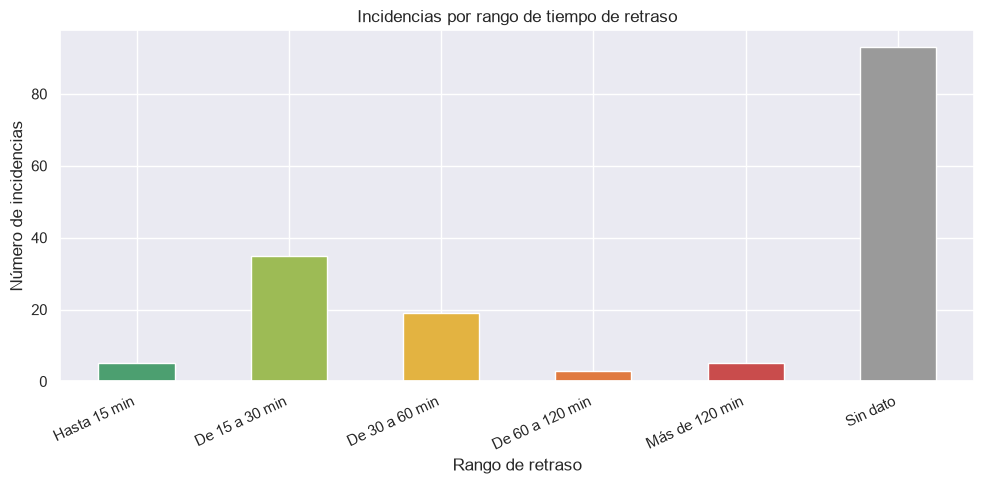

In [ ]:
# Gráfico: número de incidencias en cada rango de retraso
ax = resumen_tiempos.set_index('Rango de retraso')['Incidencias'].plot(
    kind='bar',
    figsize=(10, 5),
    color=['#4C9F70', '#9DBB55', '#E3B341', '#E07A3F', '#C94C4C', '#9A9A9A'],
    edgecolor='white'
)
ax.set_title('Incidencias por rango de tiempo de retraso')
ax.set_xlabel('Rango de retraso')
ax.set_ylabel('Número de incidencias')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()